In [1]:
!git clone https://github.com/pedropro/TACO.git
%cd TACO

Cloning into 'TACO'...
remote: Enumerating objects: 762, done.
remote: Counting objects: 100% (322/322), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 762 (delta 299), reused 306 (delta 296), pack-reused 440 (from 1)
Receiving objects: 100% (762/762), 109.46 MiB | 16.73 MiB/s, done.
Resolving deltas: 100% (509/509), done.
/content/TACO


In [2]:
!python download.py

Note. If for any reason the connection is broken. Just call me again and I will start where I left.
Finished


In [3]:
import json
import os
import shutil
import random
from collections import Counter

# 1. Load annotations
with open("data/annotations.json", "r") as f:
    coco = json.load(f)

cat_id_to_name = {c["id"]: c["name"] for c in coco["categories"]}

# Map TACO fine-grained categories into 4 clean target classes
CLASS_MAP = {
    # 0: bottle
    "Clear plastic bottle": 0, "Other plastic bottle": 0, "Glass bottle": 0,
    # 1: can
    "Drink can": 1, "Food can": 1, "Aerosol": 1,
    # 2: paper_cardboard
    "Other carton": 2, "Corrugated carton": 2, "Drink carton": 2, "Egg carton": 2,
    "Meal carton": 2, "Pizza box": 2, "Paper cup": 2, "Normal paper": 2,
    "Tissues": 2, "Wrapping paper": 2, "Paper bag": 2, "Magazine paper": 2,
    # 3: plastic_wrapper
    "Plastic film": 3, "Crisp packet": 3, "Single-use carrier bag": 3,
    "Garbage bag": 3, "Other plastic wrapper": 3, "Polypropylene bag": 3
}

TARGET_NAMES = ["bottle", "can", "paper_cardboard", "plastic_wrapper"]

# Group annotations by image_id
img_to_anns = {}
for ann in coco["annotations"]:
    cat_name = cat_id_to_name.get(ann["category_id"])
    if cat_name in CLASS_MAP:
        img_to_anns.setdefault(ann["image_id"], []).append((CLASS_MAP[cat_name], ann["bbox"]))

# Filter images that actually exist on disk and have valid target annotations
valid_images = []
for img in coco["images"]:
    img_path = os.path.join("data", img["file_name"])
    if os.path.exists(img_path) and img["id"] in img_to_anns:
        valid_images.append(img)

print(f"Total valid images with target waste classes: {len(valid_images)}")

# 2. Setup YOLO directory structure
base_dir = "/content/cleansight_yolo"
if os.path.exists(base_dir):
    shutil.rmtree(base_dir)

for split in ["train", "val"]:
    os.makedirs(f"{base_dir}/images/{split}", exist_ok=True)
    os.makedirs(f"{base_dir}/labels/{split}", exist_ok=True)

# 3. Train/Val Split (80/20) & Convert BBoxes
random.seed(42)
random.shuffle(valid_images)
split_idx = int(0.8 * len(valid_images))
splits = {"train": valid_images[:split_idx], "val": valid_images[split_idx:]}

class_counts = Counter()

for split, imgs in splits.items():
    for idx, img in enumerate(imgs):
        src_img = os.path.join("data", img["file_name"])
        ext = os.path.splitext(img["file_name"])[1]
        new_name = f"{split}_{idx:04d}"

        shutil.copy(src_img, f"{base_dir}/images/{split}/{new_name}{ext}")

        w_img, h_img = img["width"], img["height"]
        label_lines = []
        for cls_id, bbox in img_to_anns[img["id"]]:
            # COCO bbox: [x_min, y_min, width, height] -> YOLO normalized: [x_center, y_center, w, h]
            x_min, y_min, bw, bh = bbox
            x_center = max(0.0, min(1.0, (x_min + bw / 2.0) / w_img))
            y_center = max(0.0, min(1.0, (y_min + bh / 2.0) / h_img))
            nw = max(0.0, min(1.0, bw / w_img))
            nh = max(0.0, min(1.0, bh / h_img))
            label_lines.append(f"{cls_id} {x_center:.6f} {y_center:.6f} {nw:.6f} {nh:.6f}")
            class_counts[TARGET_NAMES[cls_id]] += 1

        with open(f"{base_dir}/labels/{split}/{new_name}.txt", "w") as lf:
            lf.write("\n".join(label_lines))

# 4. Write data.yaml
yaml_content = f"""path: {base_dir}
train: images/train
val: images/val

nc: {len(TARGET_NAMES)}
names: {TARGET_NAMES}
"""
with open(f"{base_dir}/clean_sight.yaml", "w") as yf:
    yf.write(yaml_content)

print(f"Train images: {len(splits['train'])} | Val images: {len(splits['val'])}")
print("Total objects per class:", dict(class_counts))
print("YOLO dataset ready at:", base_dir)

Total valid images with target waste classes: 1066
Train images: 852 | Val images: 214
Total objects per class: {'can': 239, 'plastic_wrapper': 845, 'paper_cardboard': 488, 'bottle': 439}
YOLO dataset ready at: /content/cleansight_yolo


In [4]:
!pip install -q ultralytics

from ultralytics import YOLO

model = YOLO("yolov8s.pt")

results = model.train(
    data="/content/cleansight_yolo/clean_sight.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    project="/content/cleansight_runs",
    name="waste_detector_v1"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cleansight_yolo/clean_sight.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fra

In [5]:
import shutil
from ultralytics import YOLO
from google.colab import files

# 1. Export best model to ONNX for fast CPU deployment (Project brief recommendation)
best_pt_path = "/content/cleansight_runs/waste_detector_v1/weights/best.pt"
model = YOLO(best_pt_path)
model.export(format="onnx", imgsz=640)

# 2. Bundle weights + evaluation charts into a single ZIP
shutil.make_archive(
    "/content/CleanSight_ML_Deliverables",
    "zip",
    "/content/cleansight_runs/waste_detector_v1"
)

print("ZIP created! Downloading now...")
files.download("/content/CleanSight_ML_Deliverables.zip")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs

PyTorch: starting from '/content/cleansight_runs/waste_detector_v1/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 8, 8400) (21.5 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 318ms
Prepared 4 packages in 582ms
Installed 4 packages in 35ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.32.0
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ON

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
inference_code = '''import cv2
from collections import Counter
from ultralytics import YOLO

# Load trained CleanSight model once at startup
MODEL_PATH = "best.pt"  # or "best.onnx" for CPU-only servers
model = YOLO(MODEL_PATH)

# Color map (BGR) for bounding boxes
COLORS = {
    "bottle": (255, 144, 30),          # Blue
    "can": (0, 215, 255),              # Yellow
    "paper_cardboard": (0, 200, 0),    # Green
    "plastic_wrapper": (0, 69, 255),   # Orange-Red
}

def detect_image(image_path: str, output_path: str = "annotated_output.jpg", conf_threshold: float = 0.25):
    """
    Runs litter detection on an image, saves annotated image with bounding boxes,
    and returns structured detections & counts for FastAPI POST /detect.
    """
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"Could not read image at {image_path}")

    results = model.predict(source=img, conf=conf_threshold, verbose=False)[0]

    detections = []
    counts = Counter()

    for box in results.boxes:
        cls_id = int(box.cls[0])
        cls_name = model.names[cls_id]
        confidence = round(float(box.conf[0]), 3)
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

        counts[cls_name] += 1
        detections.append({
            "class": cls_name,
            "confidence": confidence,
            "bbox": [x1, y1, x2, y2]
        })

        # Draw bounding box and label with OpenCV
        color = COLORS.get(cls_name, (255, 255, 255))
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        label = f"{cls_name} {confidence:.2f}"
        cv2.putText(img, label, (x1, max(y1 - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

    cv2.imwrite(output_path, img)

    return {
        "total_items": sum(counts.values()),
        "counts": dict(counts),
        "detections": detections,
        "annotated_image_path": output_path
    }

def analyze_video(video_path: str, output_path: str = "annotated_video.mp4", frame_skip: int = 5, conf_threshold: float = 0.25):
    """
    Processes short video for FastAPI POST /analyze-video.
    """
    cap = cv2.VideoCapture(video_path)
    fps = int(cap.get(cv2.CAP_PROP_FPS)) or 24
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    out = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))
    frame_idx = 0
    max_counts_per_frame = Counter()

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        if frame_idx % frame_skip == 0:
            results = model.predict(source=frame, conf=conf_threshold, verbose=False)[0]
            frame_counts = Counter()
            for box in results.boxes:
                cls_name = model.names[int(box.cls[0])]
                conf = float(box.conf[0])
                x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
                frame_counts[cls_name] += 1
                color = COLORS.get(cls_name, (255, 255, 255))
                cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
                cv2.putText(frame, f"{cls_name} {conf:.2f}", (x1, max(y1 - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

            for k, v in frame_counts.items():
                max_counts_per_frame[k] = max(max_counts_per_frame[k], v)

        out.write(frame)
        frame_idx += 1

    cap.release()
    out.release()

    return {
        "peak_counts": dict(max_counts_per_frame),
        "annotated_video_path": output_path
    }
'''

with open("/content/inference.py", "w") as f:
    f.write(inference_code)

from google.colab import files
files.download("/content/inference.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


0: 640x640 1 bottle, 2 cans, 1 plastic_wrapper, 13.8ms
1: 640x640 1 bottle, 1 can, 1 paper_cardboard, 13.8ms
2: 640x640 1 plastic_wrapper, 13.8ms
Speed: 3.1ms preprocess, 13.8ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/demo_test


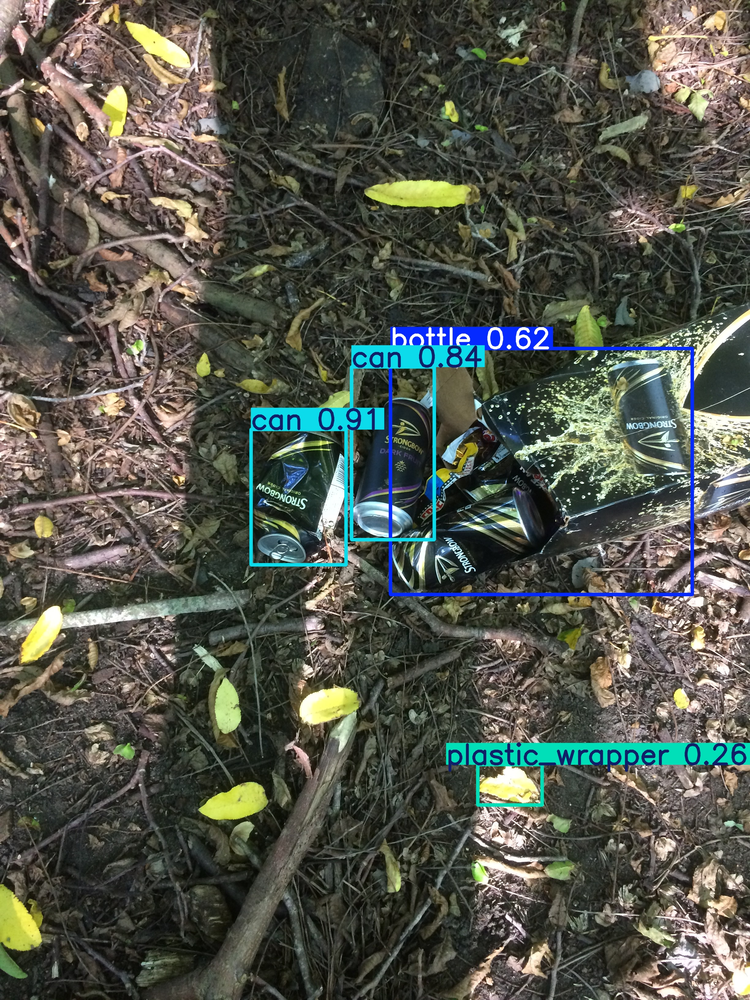

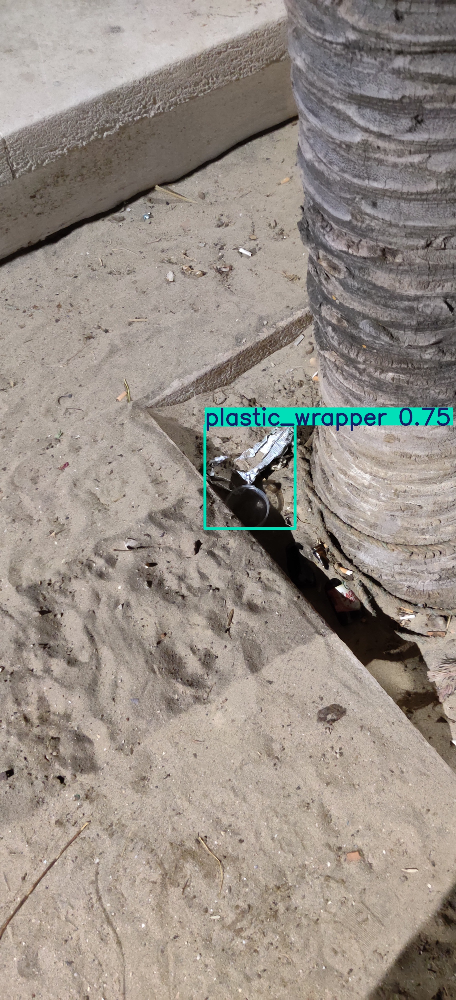

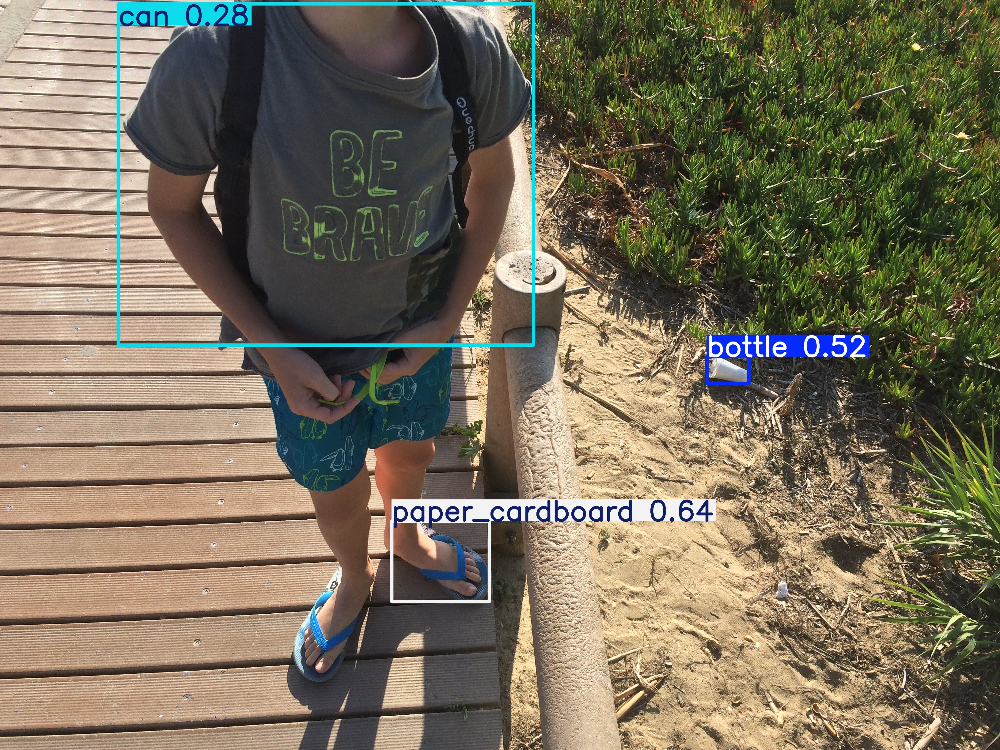

In [7]:
import glob
import random
from IPython.display import Image, display
from ultralytics import YOLO

model = YOLO("/content/cleansight_runs/waste_detector_v1/weights/best.pt")

val_images = glob.glob("/content/cleansight_yolo/images/val/*")
sample_imgs = random.sample(val_images, 3)

results = model.predict(source=sample_imgs, conf=0.25, save=True, project="/content", name="demo_test")

for img_path in glob.glob("/content/demo_test/*.jpg") + glob.glob("/content/demo_test/*.JPG") + glob.glob("/content/demo_test/*.png"):
    display(Image(filename=img_path, width=500))